In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ulnnproject/food-freshness-dataset")

print("Path to dataset files:", path)

100%|██████████| 5.89G/5.89G [01:09<00:00, 91.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ulnnproject/food-freshness-dataset/versions/1


In [ ]:
inspect_dataset()

Dataset root: /root/.cache/kagglehub/datasets/ulnnproject/food-freshness-dataset/versions/1
  [dir] Dataset -> ['Fresh', 'Rotten']

Labelled: 71318 | Could NOT parse: 0

Sample parsed paths:
  Dataset/Rotten/RottenBanana/vertical_flip_Screen Shot 2018-06-12 at 9.11.27 PM.png -> food=rottenbanana, rotten
  Dataset/Rotten/RottenApple/vertical_flip_Screen Shot 2018-06-08 at 2.42.38 PM.png -> food=rottenapple, rotten
  Dataset/Fresh/FreshOrange/images412_jpg.rf.298d74057f25c43a30794dcecd9fc7e3.jpg -> food=freshorange, fresh
  Dataset/Rotten/RottenBanana/translation_Screen Shot 2018-06-12 at 9.13.28 PM.png -> food=rottenbanana, rotten
  Dataset/Fresh/FreshApple/freshApple (702).png                -> food=freshapple, fresh
  Dataset/Fresh/FreshTomato/o (490).jpg                        -> food=freshtomato, fresh
  Dataset/Fresh/FreshTomato/o (927).jpg                        -> food=freshtomato, fresh
  Dataset/Fresh/FreshTomato/freshTomato (120).png              -> food=freshtomato, fresh

Im

'/root/.cache/kagglehub/datasets/ulnnproject/food-freshness-dataset/versions/1'

In [ ]:
"""
Food Freshness Dataset -> multi-task model (v2)

  Head 1 "food"  : which food it is
  Head 2 "fresh" : rotten (0) vs fresh (1)

Prediction:
  - SEMI-FRESH if |P(fresh) - P(rotten)| < SEMI_MARGIN
  - "Unknown food" if food confidence < FOOD_CONF_MIN
  - ESTIMATED shelf life (heuristic) = avg_shelf_life[food] * P(fresh)

Colab / Jupyter usage (paste or %run this file, then call the functions):
    inspect_dataset()              # STEP 1: verify parse_label() works
    train()                        # STEP 2
    predict("/content/apple.jpg")  # STEP 3
    gradcam("/content/apple.jpg", head="fresh")

Terminal usage:
    python food_freshness.py inspect|train
    python food_freshness.py predict img.jpg
    python food_freshness.py gradcam img.jpg [food|fresh]
"""
import os, re, sys, json, random
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

# ----------------------------------------------------------------- CONFIG
IMG_SIZE = 160            # try 224 for more accuracy (slower)
BATCH = 32
EPOCHS_HEAD = 10          # backbone frozen
EPOCHS_FINE = 10          # top of backbone unfrozen (BatchNorm stays frozen)
SEED = 42
LOSS_WEIGHTS = {"food": 1.0, "fresh": 1.5}
SEMI_MARGIN = 0.30        # |P(fresh)-P(rotten)| below this => semi-fresh
FOOD_CONF_MIN = 0.50      # below this => "Unknown food"
ZERO_DAYS_IF_ROTTEN = True
MODEL_PATH = "food_freshness_model.keras"
META_PATH = "food_freshness_meta.json"

def get_data_dir():
    import kagglehub      # pip install kagglehub  (needed on Colab)
    return kagglehub.dataset_download("ulnnproject/food-freshness-dataset")

# Average shelf life (days) of a FRESH item. Rough estimates - EDIT THESE.
# Keys are matched as lowercase substrings of the predicted food name.
AVG_SHELF_LIFE = {
    "apple": 30, "banana": 6, "orange": 21, "mango": 7, "tomato": 7,
    "potato": 60, "carrot": 28, "cucumber": 7, "capsicum": 10, "pepper": 10,
    "grape": 7, "strawberry": 5, "lemon": 21, "pomegranate": 60,
    "guava": 5, "papaya": 5, "pineapple": 5, "watermelon": 10,
    "okra": 5, "bitter": 5, "gourd": 7, "onion": 60,
}
DEFAULT_SHELF_LIFE = 7

# ------------------------------------------------------- DATA DISCOVERY
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
FRESH_WORDS = ("fresh",)
ROTTEN_WORDS = ("rotten", "rot", "stale", "spoiled", "spoilt")
IGNORE_WORDS = ("train", "test", "val", "valid", "validation", "dataset",
                "data", "images", "image", "food")

def parse_label(path, root):
    """Food name + freshness from folder names (Fresh_Apple, apple_rotten,
    Apple/Fresh ...). EDIT HERE if inspect_dataset() shows wrong parsing."""
    rel_parts = os.path.relpath(os.path.dirname(path), root).split(os.sep)
    fresh, food_tokens = None, []
    for part in rel_parts:
        for t in [t for t in re.split(r"[^a-z]+", part.lower()) if t]:
            if t in FRESH_WORDS:
                fresh = 1
            elif t in ROTTEN_WORDS:
                fresh = 0
            elif t not in IGNORE_WORDS:
                food_tokens.append(t)
    return ("_".join(food_tokens) or None), fresh

def scan(root):
    labelled, unparsed = [], []
    for dp, _, fs in os.walk(root):
        for f in fs:
            if f.lower().endswith(IMG_EXT):
                p = os.path.join(dp, f)
                food, fresh = parse_label(p, root)
                (labelled if food and fresh is not None else unparsed).append(
                    (p, food, fresh))
    return labelled, unparsed

def inspect_dataset(root=None):
    """STEP 1 - run this first and eyeball the output."""
    root = root or get_data_dir()
    print("Dataset root:", root)
    for d in sorted(os.listdir(root))[:15]:
        sub = os.path.join(root, d)
        if os.path.isdir(sub):
            print("  [dir]", d, "->", sorted(os.listdir(sub))[:8])
    labelled, unparsed = scan(root)
    print(f"\nLabelled: {len(labelled)} | Could NOT parse: {len(unparsed)}")
    for p, _, _ in unparsed[:5]:
        print("  unparsed:", os.path.relpath(p, root))
    print("\nSample parsed paths:")
    for p, fo, fr in random.Random(1).sample(labelled, min(8, len(labelled))):
        print(f"  {os.path.relpath(p, root):60s} -> food={fo}, "
              f"{'fresh' if fr else 'rotten'}")
    from collections import Counter
    c = Counter((fo, 'fresh' if fr else 'rotten') for _, fo, fr in labelled)
    print("\nImages per (food, state):")
    for k in sorted(c):
        print(f"  {k}: {c[k]}")
    foods = sorted({fo for _, fo, _ in labelled})
    print(f"\n{len(foods)} food classes: {foods}")
    return root

# ----------------------------------------------------------- PIPELINE
def make_ds(paths, food_ids, fresh_ids, training, food_w=None, fresh_w=None):
    def load(p, fo, fr):
        img = tf.io.read_file(p)
        img = tf.image.decode_image(img, channels=3, expand_animations=False)
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
        img.set_shape((IMG_SIZE, IMG_SIZE, 3))
        y = {"food": fo, "fresh": fr}
        if training and food_w is not None:           # class balancing
            sw = {"food": tf.gather(food_w, fo), "fresh": tf.gather(fresh_w, fr)}
            return img, y, sw
        return img, y

    ds = tf.data.Dataset.from_tensor_slices((paths, food_ids, fresh_ids))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

def build_model(n_food):
    aug = tf.keras.Sequential([
        layers.RandomFlip("horizontal"), layers.RandomRotation(0.1),
        layers.RandomZoom(0.1), layers.RandomContrast(0.1)], name="augment")
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = aug(inp)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)       # = MobileNetV2 preprocess
    base = MobileNetV2(include_top=False, weights="imagenet",
                       input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3)(x)
    food = layers.Dense(n_food, activation="softmax", name="food")(x)
    fresh = layers.Dense(2, activation="softmax", name="fresh")(x)  # [rotten, fresh]
    return models.Model(inp, {"food": food, "fresh": fresh}), base

def compile_model(model, lr):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss={"food": "sparse_categorical_crossentropy",
              "fresh": "sparse_categorical_crossentropy"},
        loss_weights=LOSS_WEIGHTS,
        metrics={"food": "accuracy", "fresh": "accuracy"})

def get_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                         restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss",
                                           save_best_only=True),
        tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.3)]

# --------------------------------------------------------------- TRAIN
def split_data(paths, food_ids, fresh_ids):
    idx = np.arange(len(paths))
    strat = food_ids * 2 + fresh_ids
    def sp(i, size, s):
        try:
            return train_test_split(i, test_size=size, random_state=SEED,
                                    stratify=s[i] if s is not None else None)
        except ValueError:                      # a class too small to stratify
            return train_test_split(i, test_size=size, random_state=SEED)
    tr, tmp = sp(idx, 0.2, strat)
    va, te = sp(tmp, 0.5, strat)
    return tr, va, te

def evaluate_detailed(model, test_ds, y_food, y_fresh, foods):
    import matplotlib.pyplot as plt
    out = model.predict(test_ds, verbose=0)
    pf, pr = out["food"].argmax(1), out["fresh"].argmax(1)

    print("\n===== FOOD head =====")
    print(classification_report(y_food, pf, labels=range(len(foods)),
                                target_names=foods, digits=3, zero_division=0))
    print("===== FRESHNESS head =====")
    names = ["rotten", "fresh"]
    print(classification_report(y_fresh, pr, target_names=names, digits=3))

    fig, ax = plt.subplots(1, 2, figsize=(max(10, len(foods)), 5))
    for a, (yt, yp, lab, title) in zip(ax, [
            (y_food, pf, foods, "Food"), (y_fresh, pr, names, "Freshness")]):
        cm = confusion_matrix(yt, yp, labels=range(len(lab)))
        a.imshow(cm, cmap="Blues"); a.set_title(f"{title} confusion matrix")
        a.set_xticks(range(len(lab))); a.set_xticklabels(lab, rotation=90)
        a.set_yticks(range(len(lab))); a.set_yticklabels(lab)
        for i in range(len(lab)):
            for j in range(len(lab)):
                a.text(j, i, cm[i, j], ha="center", va="center", fontsize=7)
        a.set_xlabel("Predicted"); a.set_ylabel("True")
    plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=150); plt.show()

def train():
    root = get_data_dir()
    labelled, unparsed = scan(root)
    if not labelled:
        raise RuntimeError("No labelled images - fix parse_label() "
                           "(run inspect_dataset()).")
    print(f"{len(labelled)} labelled, {len(unparsed)} skipped (unparsed)")

    foods = sorted({fo for _, fo, _ in labelled})
    f2i = {f: i for i, f in enumerate(foods)}
    paths = np.array([p for p, _, _ in labelled])
    food_ids = np.array([f2i[fo] for _, fo, _ in labelled], dtype="int32")
    fresh_ids = np.array([fr for _, _, fr in labelled], dtype="int32")

    tr, va, te = split_data(paths, food_ids, fresh_ids)

    # class balancing (sample weights, per head)
    fw = compute_class_weight("balanced", classes=np.arange(len(foods)),
                              y=food_ids[tr]).astype("float32")
    frw = compute_class_weight("balanced", classes=np.array([0, 1]),
                               y=fresh_ids[tr]).astype("float32")
    print("freshness class weights [rotten, fresh]:", frw)

    train_ds = make_ds(paths[tr], food_ids[tr], fresh_ids[tr], True, fw, frw)
    val_ds = make_ds(paths[va], food_ids[va], fresh_ids[va], False)
    test_ds = make_ds(paths[te], food_ids[te], fresh_ids[te], False)

    model, base = build_model(len(foods))

    print("\n--- Stage 1: train heads (backbone frozen) ---")
    compile_model(model, 1e-3)
    model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
              callbacks=get_callbacks())

    print("\n--- Stage 2: fine-tune top layers (BatchNorm frozen) ---")
    base.trainable = True
    for l in base.layers[:-40]:
        l.trainable = False
    for l in base.layers:                       # keep BN stats/params fixed
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False
    compile_model(model, 1e-5)                  # must recompile after changes
    model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE,
              callbacks=get_callbacks())

    model = tf.keras.models.load_model(MODEL_PATH)      # best checkpoint
    with open(META_PATH, "w") as f:
        json.dump({"foods": foods, "img_size": IMG_SIZE}, f)
    evaluate_detailed(model, test_ds, food_ids[te], fresh_ids[te], foods)
    print("Saved", MODEL_PATH, "and", META_PATH)
    return model

# ------------------------------------------------------------- PREDICT
def shelf_life_for(food):
    low = food.lower()
    for key, days in AVG_SHELF_LIFE.items():
        if key in low:
            return days
    return DEFAULT_SHELF_LIFE

def _load(model=None, foods=None):
    if model is None:
        model = tf.keras.models.load_model(MODEL_PATH)
        foods = json.load(open(META_PATH))["foods"]
    return model, foods

def _img(path):
    img = tf.keras.utils.load_img(path, target_size=(IMG_SIZE, IMG_SIZE))
    return np.expand_dims(tf.keras.utils.img_to_array(img), 0)

def predict(img_path, model=None, foods=None, verbose=True):
    model, foods = _load(model, foods)
    out = model.predict(_img(img_path), verbose=0)
    p_food, p_fresh = out["food"][0], out["fresh"][0]

    food_conf = float(p_food.max())
    food = foods[int(p_food.argmax())] if food_conf >= FOOD_CONF_MIN else "Unknown food"
    p_rot, p_fr = float(p_fresh[0]), float(p_fresh[1])

    if abs(p_fr - p_rot) < SEMI_MARGIN:
        state = "SEMI-FRESH"
    else:
        state = "FRESH" if p_fr > p_rot else "ROTTEN"

    avg_life, days = None, None
    if food != "Unknown food":
        avg_life = shelf_life_for(food)
        days = 0 if (state == "ROTTEN" and ZERO_DAYS_IF_ROTTEN) \
            else int(round(avg_life * p_fr))

    if verbose:
        print(f"Food      : {food} (confidence {food_conf*100:.1f}%)")
        print(f"Freshness : {state}  (fresh {p_fr*100:.1f}% | rotten {p_rot*100:.1f}%)")
        if days is None:
            print("Est. shelf life: n/a (food not recognised confidently)")
        else:
            print(f"Avg life of fresh {food}: {avg_life} days")
            print(f"Estimated shelf life: ~{days} day(s)  "
                  f"[heuristic = {avg_life} x {p_fr:.2f}]")
    return {"food": food, "food_conf": food_conf, "state": state,
            "p_fresh": p_fr, "p_rotten": p_rot, "est_days": days}

# ------------------------------------------------------------ GRAD-CAM
def gradcam(img_path, head="fresh", class_index=None, model=None, foods=None,
            save_path="gradcam.png"):
    """Heatmap of image regions that drove the prediction of `head`
    ('fresh' or 'food'). class_index=None -> the predicted class."""
    import matplotlib.pyplot as plt
    model, foods = _load(model, foods)
    base = next(l for l in model.layers if isinstance(l, tf.keras.Model))
    gap, head_layer = model.get_layer("gap"), model.get_layer(head)

    x = tf.convert_to_tensor(_img(img_path))
    xin = x / 127.5 - 1.0
    with tf.GradientTape() as tape:
        fmap = base(xin, training=False)
        tape.watch(fmap)
        preds = head_layer(gap(fmap))
        ci = int(tf.argmax(preds[0])) if class_index is None else class_index
        score = preds[:, ci]
    grads = tape.gradient(score, fmap)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(fmap * w[:, None, None, :], axis=-1))[0]
    cam = (cam / (tf.reduce_max(cam) + 1e-8)).numpy()
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]

    label = (["rotten", "fresh"] if head == "fresh" else foods)[ci]
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(x[0].numpy().astype("uint8")); ax[0].set_title("Input")
    ax[1].imshow(x[0].numpy().astype("uint8"))
    ax[1].imshow(cam, cmap="jet", alpha=0.45)
    ax[1].set_title(f"Grad-CAM: {head} = {label} ({float(preds[0][ci])*100:.0f}%)")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.savefig(save_path, dpi=150); plt.show()

# ------------------------------------------------------------------ CLI
def _in_notebook():
    return "ipykernel" in sys.modules

if __name__ == "__main__":
    if _in_notebook():
        print("Loaded. Now call: inspect_dataset(), train(), "
              "predict(path), gradcam(path)")
    else:
        a = sys.argv[1:]
        if a[:1] == ["inspect"]:
            inspect_dataset()
        elif a[:1] == ["train"]:
            train()
        elif a[:1] == ["predict"] and len(a) > 1:
            predict(a[1])
        elif a[:1] == ["gradcam"] and len(a) > 1:
            gradcam(a[1], head=a[2] if len(a) > 2 else "fresh")
        else:
            print(__doc__)

Loaded. Now call: inspect_dataset(), train(), predict(path), gradcam(path)


Using Colab cache for faster access to the 'food-freshness-dataset' dataset.
71318 labelled, 0 skipped (unparsed)
freshness class weights [rotten, fresh]: [1.4872531 0.7532279]

--- Stage 1: train heads (backbone frozen) ---
Epoch 1/10
1783/1783 ━━━━━━━━━━━━━━━━━━━━ 252s 135ms/step - food_accuracy: 0.8211 - food_loss: 0.5734 - fresh_accuracy: 0.8793 - fresh_loss: 0.2972 - loss: 1.0192 - val_food_accuracy: 0.8863 - val_food_loss: 0.3632 - val_fresh_accuracy: 0.9037 - val_fresh_loss: 0.2576 - val_loss: 0.7493 - learning_rate: 0.0010
Epoch 2/10
1783/1783 ━━━━━━━━━━━━━━━━━━━━ 186s 104ms/step - food_accuracy: 0.8894 - food_loss: 0.3104 - fresh_accuracy: 0.8954 - fresh_loss: 0.2655 - loss: 0.7088 - val_food_accuracy: 0.9222 - val_food_loss: 0.2352 - val_fresh_accuracy: 0.9061 - val_fresh_loss: 0.2500 - val_loss: 0.6098 - learning_rate: 0.0010
Epoch 3/10
1783/1783 ━━━━━━━━━━━━━━━━━━━━ 201s 104ms/step - food_accuracy: 0.8973 - food_loss: 0.2843 - fresh_accuracy: 0.8965 - fresh_loss: 0.2666 - l

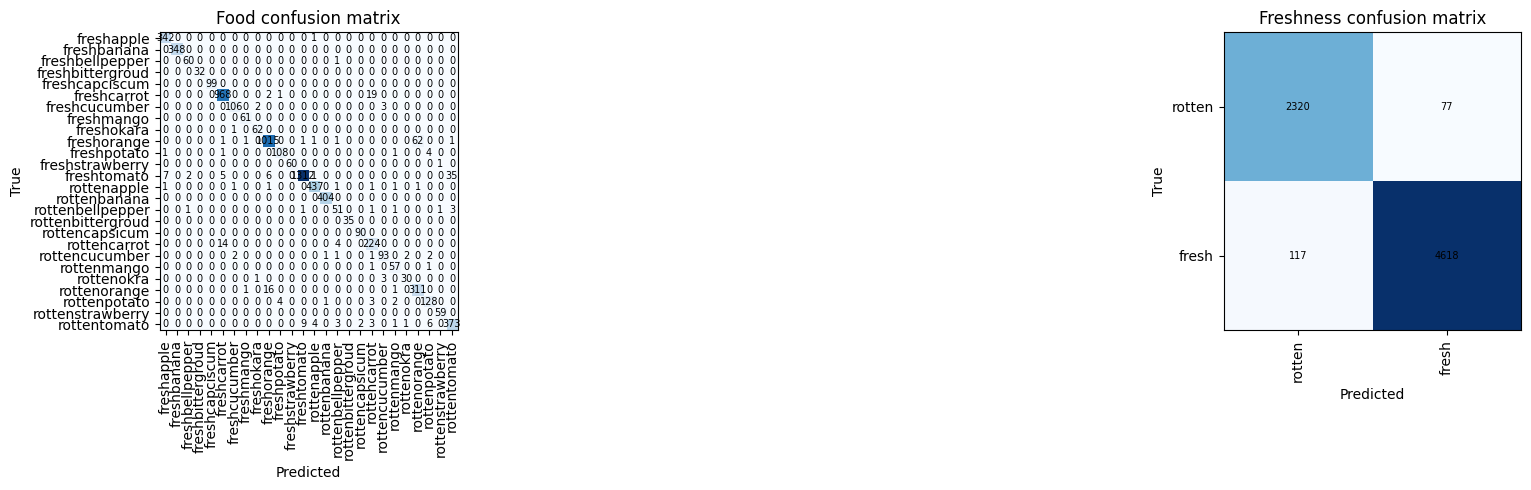

Saved food_freshness_model.keras and food_freshness_meta.json


In [ ]:
model = train()

In [ ]:
predict("app.avif")

Food      : freshapple (confidence 100.0%)
Freshness : FRESH  (fresh 100.0% | rotten 0.0%)
Avg life of fresh freshapple: 30 days
Estimated shelf life: ~30 day(s)  [heuristic = 30 x 1.00]


{'food': 'freshapple',
 'food_conf': 0.9999898672103882,
 'state': 'FRESH',
 'p_fresh': 0.9999746084213257,
 'p_rotten': 2.5443732738494873e-05,
 'est_days': 30}

In [ ]:
predict("images.jpg")

Food      : rottenapple (confidence 98.9%)
Freshness : ROTTEN  (fresh 0.0% | rotten 100.0%)
Avg life of fresh rottenapple: 30 days
Estimated shelf life: ~0 day(s)  [heuristic = 30 x 0.00]


{'food': 'rottenapple',
 'food_conf': 0.9888474941253662,
 'state': 'ROTTEN',
 'p_fresh': 1.9269343738415046e-06,
 'p_rotten': 0.9999980926513672,
 'est_days': 0}

In [ ]:
shelf_life_for("apple")

30

# Model Training & Performance Summary

### 1. Dataset Overview
* **Source**: `ulnnproject/food-freshness-dataset` (via `kagglehub`)
* **Size**: 71,318 labelled images spanning 26 distinct categories representing combination of food type and condition.
* **Key Classes**: Combinations of fresh/rotten apples, bananas, bell peppers, carrots, tomatoes, oranges, potatoes, etc.

### 2. Model Architecture & Approach
* **Backbone**: `MobileNetV2` pretrained on ImageNet.
* **Multi-Task Strategy**: Dual classification heads built on top of the shared feature extraction backbone:
  * **Food Classification Head**: Softmax classifier predicting 1 of 26 categories.
  * **Freshness Classification Head**: Binary softmax classifier predicting state (`[rotten, fresh]`).
* **Input Size**: $160 \times 160$ pixels (RGB).
* **Data Augmentation**: Random flip, rotation (0.1), zoom (0.1), and contrast (0.1).

### 3. Hyperparameters & Settings
* **Optimizer**: Adam
* **Initial Learning Rate**:
  * **Stage 1**: `1e-3` (backbone frozen)
  * **Stage 2**: `1e-5` (top 40 layers of backbone unfrozen, BatchNorm frozen)
* **Batch Size**: 32
* **Loss Functions**: Sparse Categorical Crossentropy for both heads.
* **Loss Weights**: `{'food': 1.0, 'fresh': 1.5}`
* **Regularization**: Dropout (0.3) prior to classification heads.
* **Class Balancing**: Balanced class weights applied to the training dataset (`[1.487, 0.753]` for freshness).

### 4. Training Execution & Results
* **Stage 1 (Heads Only)**: Started with validation loss of `0.749` and stabilized around `0.514` by Epoch 9 with a learning rate drop to `9.0000e-05`.
* **Stage 2 (Fine-Tuning)**: Further improved performance by optimizing lower layers with a very conservative learning rate.

### 5. Final Evaluation Metrics (Test Set)
* **Overall Accuracy (Food Category)**: **96.3%**
* **Overall Accuracy (Freshness State)**: **97.3%**

#### Classification Report Highlights
* **Freshness Head**:
  * **Rotten**: Precision: `0.952` | Recall: `0.968` | F1-Score: `0.960`
  * **Fresh**: Precision: `0.984` | Recall: `0.975` | F1-Score: `0.979`
* **Food Head (Sample Classes)**:
  * `rottenmango`: F1-Score: `0.927`
  * `rottentomato`: F1-Score: `0.916`
  * `rottenstrawberry`: F1-Score: `0.983`